# 02 · Profili di gusto (#Caratteri)

Per misurare quanto vale una domanda serve un **bersaglio**: il profilo di gusto di ogni persona. In questo notebook lo costruisco con tre scelte di metodo, ciascuna motivata:

1. **Divido il catalogo in due.** Una parte dei dolci serve a *definire* il profilo; l'altra parte è il *serbatoio di domande* del notebook 03. Così il test dovrà indovinare il gusto su prodotti che **non ha chiesto**, ed evito che domande e risposta coincidano (circolarità).
2. **Descrivo il gusto per attributo sensoriale** (cioccolato, frutta, menta…) e non dolce per dolce. Con 38 dolci valutati sì/no, i profili dolce per dolce risultano instabili. Riassumere per attributo riduce il rumore ed è il modo in cui ragiona un modello sensoriale.
3. **Scelgo il numero di profili in base alla stabilità** al ricampionamento.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from catalogo import ATTRIBUTI
from stile_grafici import applica_stile, salva, CATEGORIALE, BLU, ARANCIO, GRIGIO, TESTO_2

applica_stile()
SEED = 42

M = pd.read_csv("../data/processed/valutazioni_2015.csv", index_col="persona")
ctx = pd.read_csv("../data/processed/contesto_2015.csv", index_col="persona")
cat = pd.read_csv("../data/processed/catalogo.csv").set_index("dolce")
print(f"Rispondenti: {len(M):,} · Dolci: {M.shape[1]}")

Rispondenti: 4,579 · Dolci: 57


## 1. Due metà del catalogo: profilo e domande

Divido i 57 dolci in **due terzi per il profilo** (38) e **un terzo come serbatoio di domande** (19). La divisione è casuale ma **stratificata per attributo principale**: ogni gusto deve essere rappresentato in entrambe le parti.

In [2]:
ORDINE = ["liquirizia", "menta", "arachidi", "caramello", "cioccolato", "frutta"]   # dal più raro al più comune
def attributo_principale(dolce):
    for a in ORDINE:
        if cat.loc[dolce, a]:
            return a
    return "nessuno"
cat["principale"] = [attributo_principale(d) for d in cat.index]

def dividi(seed, quota=2/3):
    rng = np.random.default_rng(seed)
    profilo, domande = [], []
    for g in ORDINE + ["nessuno"]:
        dolci = list(rng.permutation(cat.index[cat["principale"] == g]))
        n = int(round(len(dolci) * quota))
        profilo += dolci[:n]; domande += dolci[n:]
    return profilo, domande

PROFILO, DOMANDE = dividi(SEED)
riepilogo = pd.DataFrame({
    "dolci per il profilo": cat.loc[PROFILO, ATTRIBUTI].sum(),
    "dolci nel serbatoio domande": cat.loc[DOMANDE, ATTRIBUTI].sum(),
})
print(f"Profilo: {len(PROFILO)} dolci · Serbatoio di domande: {len(DOMANDE)} dolci\n")
print("Serbatoio di domande:", ", ".join(DOMANDE), "\n")
riepilogo

Profilo: 38 dolci · Serbatoio di domande: 19 dolci

Serbatoio di domande: Black Jacks, Mint Juleps, Reese's Peanut Butter Cups, Peanut M&M's, Chick-o-Sticks, Rolos, Mars, 100 Grand, Lindt Truffle, M&M's, Cadbury Creme Eggs, Nerds, Bonkers, Pixy Stix, Swedish Fish, Skittles, Circus Peanuts, Necco Wafers, Hard Candy 



,dolci per il profilo,dolci nel serbatoio domande
cioccolato,18,8
frutta,13,6
menta,3,1
arachidi,6,3
caramello,7,3
liquirizia,2,1


## 2. Dal "mi piace" per dolce al profilo sensoriale

Per ogni persona e ogni attributo calcolo il **gradimento relativo**: quanta gioia le danno i dolci con quell'attributo, *rispetto alla sua media*. Il confronto è con la sua media perché alcune persone amano quasi tutto e altre quasi niente; ciò che distingue i gusti è che cosa una persona preferisce *rispetto al resto*, non quanto è generosa.

Poi standardizzo ogni attributo (media 0, deviazione 1), così che nessuno pesi più degli altri solo perché ha una scala più ampia.

In [3]:
def punteggi_attributo(valutazioni, dolci):
    X = valutazioni[dolci]
    relativo = X.sub(X.mean(axis=1), axis=0)
    return pd.DataFrame({a: relativo[[d for d in dolci if cat.loc[d, a]]].mean(axis=1) for a in ATTRIBUTI}).fillna(0)

S = punteggi_attributo(M, PROFILO)
MEDIA, DEV = S.mean(), S.std()
Z = (S - MEDIA) / DEV

print("Gradimento medio per attributo (quota di 'gioia', 2015):")
print(pd.Series({a: M[[d for d in PROFILO if cat.loc[d, a]]].stack().mean() for a in ATTRIBUTI}).round(2).to_string())
Z.describe().round(2)

Gradimento medio per attributo (quota di 'gioia', 2015):
cioccolato    0.66
frutta        0.41
menta         0.56
arachidi      0.51
caramello     0.66
liquirizia    0.27


,cioccolato,frutta,menta,arachidi,caramello,liquirizia
count,4579.00,4579.00,4579.00,4579.00,4579.00,4579.00
mean,0.00,-0.00,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-5.54,-3.07,-2.61,-4.20,-3.95,-1.96
25%,-0.65,-0.69,-0.84,-0.64,-0.66,-0.77
50%,0.03,-0.00,0.19,0.04,0.05,-0.30
75%,0.70,0.68,0.80,0.67,0.72,0.66
max,3.07,4.15,2.31,3.43,2.98,3.23


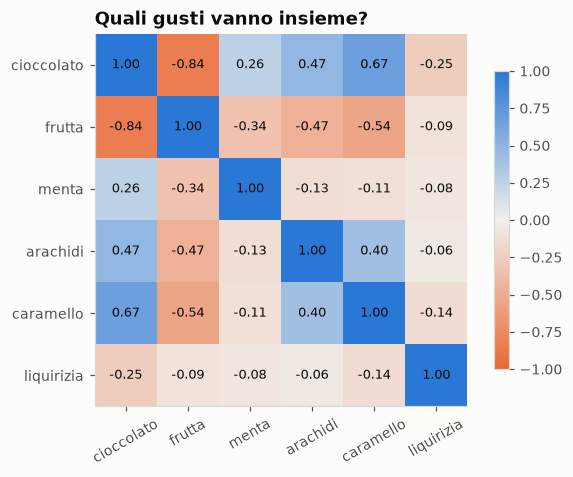

In [4]:
fig, ax = plt.subplots(figsize=(6.2, 4.4))
corr = S.corr()
cmap = LinearSegmentedColormap.from_list("div", [ARANCIO, "#f1f0ed", BLU])
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5, color="#0b0b0b")
ax.set_xticks(range(len(corr)), corr.columns, rotation=30); ax.set_yticks(range(len(corr)), corr.columns)
ax.set_title("Quali gusti vanno insieme?"); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
salva(fig, "02_correlazioni_attributi")
plt.show()

La struttura è chiara: **cioccolato, arachidi e caramello vanno insieme** (le barrette classiche) e sono **opposti alla frutta**. È la divisione principale del gusto per i dolci. Menta e liquirizia sono dimensioni a parte, quasi indipendenti dalle altre.

## 3. Quanti profili?

Uso due criteri: **silhouette** (separazione) e **stabilità al bootstrap** (ARI). Se ricampiono le persone e rifaccio la segmentazione, ritrovo gli stessi gruppi? Sopra 0,85 la soluzione è considerata stabile.

In [5]:
rng = np.random.default_rng(SEED)
B = 50
righe = []
for k in range(2, 8):
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z.values)
    sil = silhouette_score(Z.values, km.labels_, sample_size=3000, random_state=SEED)
    ari = []
    for b in range(B):
        idx = rng.choice(len(Z), len(Z), replace=True)
        kb = KMeans(k, n_init=20, random_state=b).fit(Z.values[idx])
        ari.append(adjusted_rand_score(km.labels_, kb.predict(Z.values)))
    righe.append({"k": k, "silhouette": sil, "stabilità_ARI": np.mean(ari), "ARI_p5": np.percentile(ari, 5),
                  "gruppo_più_piccolo": np.bincount(km.labels_).min()})
scelta_k = pd.DataFrame(righe)
scelta_k.round(3)

,k,silhouette,stabilità_ARI,ARI_p5,gruppo_più_piccolo
0,2,0.247,0.953,0.896,2183
1,3,0.201,0.725,0.269,1171
2,4,0.184,0.682,0.348,989
3,5,0.203,0.838,0.748,721
4,6,0.201,0.887,0.808,561
5,7,0.201,0.736,0.514,395


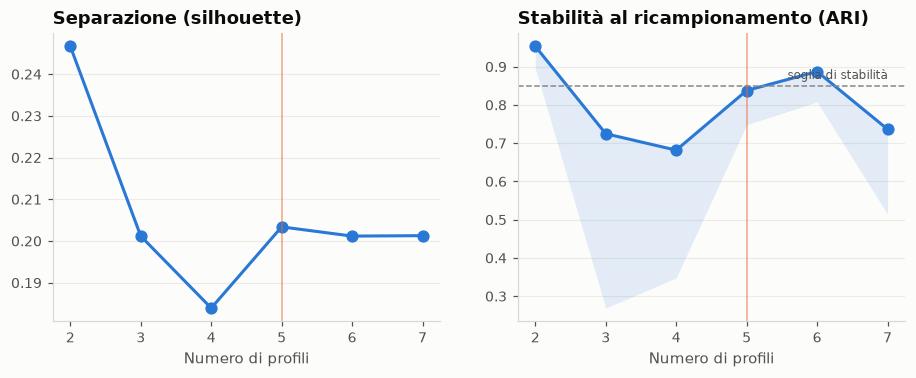

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(scelta_k["k"], scelta_k["silhouette"], marker="o", color=BLU, markersize=7)
axes[0].set_title("Separazione (silhouette)")
axes[1].plot(scelta_k["k"], scelta_k["stabilità_ARI"], marker="o", color=BLU, markersize=7)
axes[1].fill_between(scelta_k["k"], scelta_k["ARI_p5"], scelta_k["stabilità_ARI"], color=BLU, alpha=0.12, linewidth=0)
axes[1].axhline(0.85, color=GRIGIO, linestyle="--", linewidth=1)
axes[1].text(7, 0.86, "soglia di stabilità", ha="right", va="bottom", fontsize=8, color=TESTO_2)
axes[1].set_title("Stabilità al ricampionamento (ARI)")
for ax in axes:
    ax.set_xlabel("Numero di profili"); ax.axvline(5, color=ARANCIO, linewidth=1, alpha=0.6)
salva(fig, "02_scelta_numero_profili")
plt.show()

La curva di stabilità non scende in modo monotòno. Dopo i 2 profili, stabili ma banali ("cioccolato contro frutta"), cala, poi **risale a 5–6 profili**.

È un segnale tipico. Con 5–6 gruppi ogni dimensione del gusto (cioccolato/frutta, menta, liquirizia) trova il suo spazio. Con 3 o 4 gruppi l'algoritmo deve invece "decidere" ogni volta dove mettere menta e liquirizia, e la soluzione cambia ricampionando.

La silhouette è bassa per ogni *k*, ed è normale con dati di gusto: le persone non formano "isole" separate, i gusti variano con continuità. La stabilità è quindi il criterio che conta.

**5 o 6?** Con questa divisione 6 profili risultano leggermente più stabili. Prima di decidere controllo se la differenza è reale, ripetendo il confronto su altre due divisioni casuali del catalogo.

In [7]:
righe = []
for seme in [SEED, 7, 2026]:
    P_alt, _ = dividi(seme)
    S_alt = punteggi_attributo(M, P_alt)
    Z_alt = ((S_alt - S_alt.mean()) / S_alt.std()).values
    for k in [5, 6]:
        km_k = KMeans(k, n_init=50, random_state=SEED).fit(Z_alt)
        ari = []
        for b in range(B):
            idx = rng.choice(len(Z_alt), len(Z_alt), replace=True)
            ari.append(adjusted_rand_score(km_k.labels_, KMeans(k, n_init=20, random_state=100 + b).fit(Z_alt[idx]).predict(Z_alt)))
        righe.append({"divisione (seme)": seme, "k": k, "stabilità_ARI": np.mean(ari)})
cinque_sei = pd.DataFrame(righe).pivot(index="divisione (seme)", columns="k", values="stabilità_ARI")
cinque_sei.loc["media"] = cinque_sei.mean()
cinque_sei.round(3)

k,5,6
divisione (seme),,
7,0.911,0.882
42,0.846,0.898
2026,0.848,0.854
media,0.868,0.878


**Scelgo 5 profili.** Su tre divisioni diverse del catalogo, entrambe le soluzioni superano la soglia di stabilità, e la differenza media è di circa un centesimo di ARI: rientra nel rumore della stima.

A parità di stabilità vincono 5 profili, sono più facili da comunicare a un cliente e ognuno contiene più persone, quindi è stimato meglio. Il sesto profilo, inoltre, non introduce un gusto nuovo: divide gli amanti della frutta tra chi tollera la menta e chi no.

In [8]:
km = KMeans(5, n_init=50, random_state=SEED).fit(Z.values)
centri = pd.DataFrame(km.cluster_centers_, columns=ATTRIBUTI)

# Nomi assegnati in modo riproducibile in base alla "firma" sensoriale di ogni centro
FIRME = {
    "#Goloso":     {"cioccolato": 1, "arachidi": 0.5, "caramello": 0.5, "frutta": -1},
    "#Vivace":     {"frutta": 1, "cioccolato": -1},
    "#Eccentrico": {"liquirizia": 1},
    "#Fresco":     {"menta": 1},
    "#Morbido":    {"menta": -1},
}
firme = pd.DataFrame(FIRME).T.reindex(columns=ATTRIBUTI).fillna(0)
riga, colonna = linear_sum_assignment(-(firme.values @ centri.values.T))
NOME_DEL_CENTRO = {c: firme.index[r] for r, c in zip(riga, colonna)}
NOMI = list(FIRME)
etichetta = pd.Series(km.labels_, index=Z.index).map(NOME_DEL_CENTRO)
centri.index = [NOME_DEL_CENTRO[i] for i in centri.index]
centri = centri.loc[NOMI]

DESCRIZIONI = {
    "#Goloso": "Le barrette classiche: cioccolato con arachidi e caramello. Rifiuta i fruttati.",
    "#Vivace": "Fruttati e aciduli (Lollipops, Dots, Bottle Caps); rifiuta il cioccolato più ricco.",
    "#Eccentrico": "Ama la liquirizia, il gusto più divisivo del catalogo.",
    "#Fresco": "Ama la menta (York, Junior Mints); poco la liquirizia.",
    "#Morbido": "Rifiuta la menta; preferisce sapori dolci e rotondi.",
}
quota = etichetta.value_counts(normalize=True).reindex(NOMI)
pd.DataFrame({"persone": etichetta.value_counts().reindex(NOMI), "quota": quota.map("{:.0%}".format),
              "descrizione": pd.Series(DESCRIZIONI)})

,persone,quota,descrizione
#Goloso,1020,22%,Le barrette classiche: cioccolato con arachidi...
#Vivace,742,16%,"Fruttati e aciduli (Lollipops, Dots, Bottle Ca..."
#Eccentrico,721,16%,"Ama la liquirizia, il gusto più divisivo del c..."
#Fresco,1176,26%,"Ama la menta (York, Junior Mints); poco la liq..."
#Morbido,920,20%,Rifiuta la menta; preferisce sapori dolci e ro...


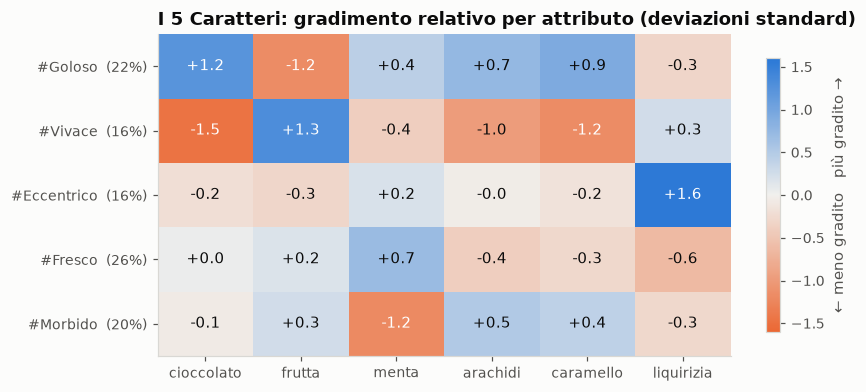

In [9]:
fig, ax = plt.subplots(figsize=(8.4, 3.8))
im = ax.imshow(centri.values, cmap=cmap, vmin=-1.6, vmax=1.6, aspect="auto")
for i in range(centri.shape[0]):
    for j in range(centri.shape[1]):
        v = centri.iloc[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9.5,
                color="white" if abs(v) > 1.0 else "#0b0b0b")
ax.set_xticks(range(len(ATTRIBUTI)), ATTRIBUTI)
ax.set_yticks(range(len(NOMI)), [f"{n}  ({quota[n]:.0%})" for n in NOMI])
ax.set_title("I 5 Caratteri: gradimento relativo per attributo (deviazioni standard)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.85, label="← meno gradito   più gradito →")
salva(fig, "02_profili_heatmap")
plt.show()

### I prodotti che distinguono ogni profilo

Per ogni Carattere, quali dolci piacciono molto più (o molto meno) rispetto alla media di tutti i rispondenti? È la lettura che un brand userebbe per decidere quali prodotti proporre a ogni segmento.

In [10]:
gioia_media = M[PROFILO].mean()
righe = []
for n in NOMI:
    diff = (M.loc[etichetta == n, PROFILO].mean() - gioia_media) * 100
    piu, meno = diff.nlargest(3), diff.nsmallest(2)
    righe.append({"carattere": n,
                  "piace molto più della media": ", ".join(f"{d} (+{v:.0f})" for d, v in piu.items()),
                  "piace molto meno": ", ".join(f"{d} ({v:.0f})" for d, v in meno.items())})
pd.DataFrame(righe).set_index("carattere")

,piace molto più della media,piace molto meno
carattere,,
#Goloso,"Heath Bar (+21), Goo Goo Clusters (+17), York ...","Laffy Taffy (-28), Gummy Bears (-26)"
#Vivace,"Lollipops (+26), Dots (+24), Bottle Caps (+23)","Heath Bar (-30), Toblerone (-26)"
#Eccentrico,"Licorice (black) (+64), Good N' Plenty (+57), ...","Hershey's Milk Chocolate (-7), Starburst (-5)"
#Fresco,"Junior Mints (+30), York Peppermint Patties (+...","Licorice (black) (-19), Good N' Plenty (-16)"
#Morbido,"Snickers (+6), Butterfinger (+5), Kinder Happy...","York Peppermint Patties (-52), Junior Mints (-52)"


## 4. Validazione

Un profilo ricavato dai dati potrebbe essere un artefatto. Faccio tre controlli, usando informazioni che **non** ho usato per costruirlo.

### 4a. I profili prevedono il gusto anche su dolci *mai usati* per costruirli?

È il test più importante. Prendo i 19 dolci del serbatoio di domande, che il clustering non ha mai visto, e calcolo per ogni profilo il gradimento relativo per attributo. Se i profili descrivono gusti reali, devono "riconoscersi" anche su questi prodotti.

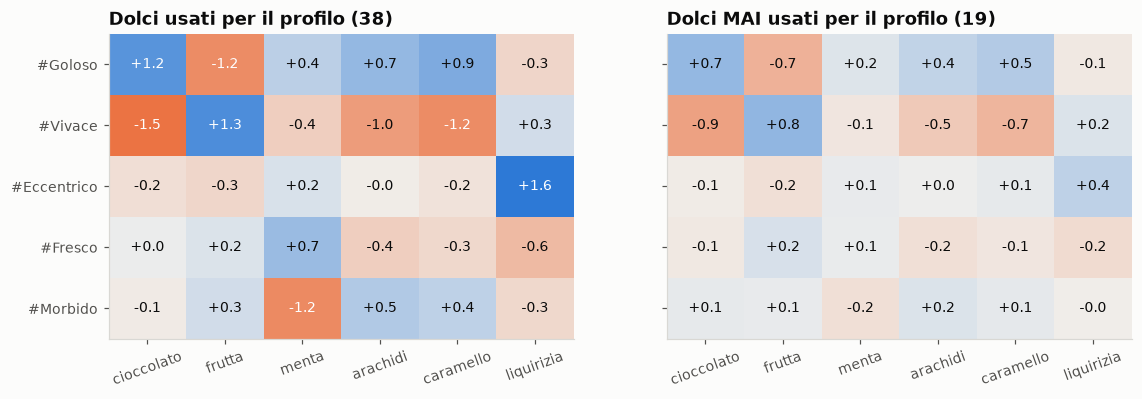

Correlazione tra i due quadri: r = 0.93


In [11]:
S_nuovi = punteggi_attributo(M, DOMANDE)
Z_nuovi = (S_nuovi - S_nuovi.mean()) / S_nuovi.std()
su_nuovi = Z_nuovi.groupby(etichetta).mean().loc[NOMI]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, tab, titolo in [(axes[0], centri, "Dolci usati per il profilo (38)"),
                        (axes[1], su_nuovi, "Dolci MAI usati per il profilo (19)")]:
    ax.imshow(tab.values, cmap=cmap, vmin=-1.6, vmax=1.6, aspect="auto")
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.iloc[i, j]
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 1.0 else "#0b0b0b")
    ax.set_xticks(range(len(ATTRIBUTI)), ATTRIBUTI, rotation=20); ax.set_title(titolo); ax.grid(False)
axes[0].set_yticks(range(len(NOMI)), NOMI)
salva(fig, "02_validazione_prodotti_nuovi")
plt.show()
r = np.corrcoef(centri.values.ravel(), su_nuovi.values.ravel())[0, 1]
print(f"Correlazione tra i due quadri: r = {r:.2f}")

Le due mappe hanno lo **stesso disegno**: i #Golosi amano il cioccolato anche tra i dolci mai visti, i #Vivaci i fruttati, gli #Eccentrici la liquirizia. I valori sono un po' più deboli, come atteso: il clustering "ottimizza" i dolci su cui è costruito.

È la proprietà che serve a un Taste Test: il profilo **generalizza a prodotti nuovi**, e quindi può essere usato per consigliarli.

### 4b. I profili sono stabili se cambio la divisione del catalogo?

La divisione dei dolci è casuale. Se la rifaccio con altri due semi, ritrovo gli stessi profili?

In [12]:
righe = []
for seme in [7, 2026]:
    P_alt, _ = dividi(seme)
    S_alt = punteggi_attributo(M, P_alt)
    Z_alt = (S_alt - S_alt.mean()) / S_alt.std()
    km_alt = KMeans(5, n_init=50, random_state=SEED).fit(Z_alt.values)
    c_alt = pd.DataFrame(km_alt.cluster_centers_, columns=ATTRIBUTI)
    r_, c_ = linear_sum_assignment(-(centri.values @ c_alt.values.T))        # abbina i profili
    mappa = {c: NOMI[r] for r, c in zip(r_, c_)}
    et_alt = pd.Series(km_alt.labels_, index=Z.index).map(mappa)
    corr_centri = np.mean([np.corrcoef(centri.iloc[r].values, c_alt.iloc[c].values)[0, 1] for r, c in zip(r_, c_)])
    righe.append({"seme": seme, "dolci in comune con la divisione principale": len(set(P_alt) & set(PROFILO)),
                  "correlazione media dei profili": corr_centri,
                  "stesse persone nello stesso profilo": (et_alt == etichetta).mean()})
pd.DataFrame(righe).round(3)

,seme,dolci in comune con la divisione principale,correlazione media dei profili,stesse persone nello stesso profilo
0,7,25,0.969,0.649
1,2026,21,0.975,0.624


Con divisioni diverse del catalogo, che condividono solo una parte dei dolci, emergono **gli stessi 5 profili**: la correlazione tra i centri è di circa 0,97. I #Caratteri non dipendono da quali dolci ho scelto; descrivono una struttura reale del gusto.

Circa **due persone su tre** finiscono nello stesso profilo. Non è il 100% perché chi sta al confine tra due profili può spostarsi quando cambiano i dolci usati per misurarlo. È un'altra conferma che i gusti variano con continuità, e un'indicazione utile per il notebook 03: per le persone "di confine" nessun test potrà essere molto preciso.

### 4c. I profili hanno senso rispetto a chi sono le persone?

In [13]:
tab = pd.crosstab(etichetta, ctx.loc[etichetta.index, "eta"]).loc[NOMI, ["<18", "18-29", "30-39", "40-49", "50+"]]
tab.index.name = "carattere"
chi2, p, _, _ = chi2_contingency(tab)
v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"Profilo × età: Cramér's V = {v:.2f}, p = {p:.1e}\n")
(tab / tab.sum() * 100).round(0)

Profilo × età: Cramér's V = 0.12, p = 1.1e-46



eta,<18,18-29,30-39,40-49,50+
carattere,,,,,
#Goloso,7.0,16.0,20.0,28.0,33.0
#Vivace,34.0,20.0,17.0,12.0,10.0
#Eccentrico,12.0,11.0,14.0,19.0,26.0
#Fresco,31.0,30.0,28.0,24.0,16.0
#Morbido,16.0,23.0,22.0,18.0,15.0


Per ogni fascia d'età, come si distribuiscono le persone tra i profili?

L'associazione con l'età è **significativa ma debole** (Cramér's V = 0,12), coerente con il notebook 01:
- i #Vivaci, amanti dei fruttati, sono il 34% dei minori di 18 anni e il 10% degli over 50;
- i #Golosi fanno il percorso opposto, dal 7% al 33%;
- gli #Eccentrici, amanti della liquirizia, crescono con l'età.

Ogni profilo, però, si trova in tutte le età.

Conseguenza per il notebook 03: chiedere l'età aiuterà un po', ma molto meno che chiedere un gusto.

## 5. Salvataggio

Salvo i profili e tutto ciò che serve per **riapplicarli a persone nuove** nel 2017: la divisione del catalogo, le medie e le deviazioni per standardizzare, i centri dei profili.

In [14]:
pd.DataFrame({"carattere": etichetta}).to_csv("../data/processed/profili_2015.csv")
pd.Series({"profilo": PROFILO, "domande": DOMANDE}).to_json("../data/processed/divisione_catalogo.json")
pd.DataFrame({"media": MEDIA, "dev_std": DEV}).to_csv("../data/processed/standardizzazione_2015.csv")
centri.to_csv("../data/processed/centri_profili_2015.csv")
etichetta.value_counts().reindex(NOMI)

#Goloso        1020
#Vivace         742
#Eccentrico     721
#Fresco        1176
#Morbido        920
Name: count, dtype: int64

## Sintesi

- **Disegno non circolare:** 38 dolci definiscono il profilo, gli altri 19 diventano le domande del test.
- **Profilo sensoriale:** gradimento relativo per sei attributi, più stabile e interpretabile della valutazione dolce per dolce.
- **5 Caratteri**, stabili al ricampionamento e scelti per parsimonia rispetto a 6, ugualmente stabile: **#Goloso** (22%), **#Vivace** (16%), **#Eccentrico** (16%), **#Fresco** (26%), **#Morbido** (20%).
- **Validazione:**
  - i profili si riconoscono su dolci *mai usati* per costruirli, quindi generalizzano a prodotti nuovi;
  - restano gli stessi cambiando la divisione del catalogo (correlazione dei centri circa 0,97);
  - sono coerenti, ma solo debolmente, con l'età.

→ **Notebook 03:** quante domande, e quali, servono per riconoscere il Carattere di una persona.